In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
%matplotlib tk

vid_filename = 'C:\\Users\\USER\\Documents\\Active_Matter\\Ran\\Videos\\old\\FRISBEE_18.mp4'
cap = cv2.VideoCapture(vid_filename)

NF = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
t_start = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000  # Convert ms to seconds

x_t = np.zeros(NF)
y_t = np.zeros(NF)
t = np.zeros(NF)


# Read and display the first frame with interactive click
ret, frame = cap.read()
if ret:
    fig, ax = plt.subplots()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.show()


def frame_isolate_green(image, dark_green=False):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    if dark_green:
        # Define thresholds for dark green
        lower_bound = np.array([35, 100, 100])
        upper_bound = np.array([85, 255, 255])
    else:
        # Define thresholds (converted from MATLAB values)
        lower_bound = np.array([37, 190, 127])  # Approximate conversion
        upper_bound = np.array([76, 255, 255])

    mask = cv2.inRange(hsv, lower_bound, upper_bound)
    masked_image = cv2.bitwise_and(image, image, mask=mask)
    return mask, masked_image

def frame_isolate_orange(image, dark_orange=False):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    if dark_orange:
        # Define thresholds for dark orange
        lower_bound = np.array([0, 150, 150])
        upper_bound = np.array([10, 255, 255])
    else:
        # Define thresholds (converted from MATLAB values)
        lower_bound = np.array([1, 175, 175])
        upper_bound = np.array([20, 255, 255])

    mask = cv2.inRange(hsv, lower_bound, upper_bound)
    masked_image = cv2.bitwise_and(image, image, mask=mask)
    return mask, masked_image

def find_circles(frame, isolate_green=False, isolate_orange=False, min_r=10, max_r=20):

    if isolate_green:
        mask, _ = frame_isolate_green(frame)

        blurred = cv2.GaussianBlur(mask, (9, 9), 2)
        edges = cv2.Canny(blurred, 50, 150)

        circles = cv2.HoughCircles(edges, cv2.HOUGH_GRADIENT, dp=1.2, minDist=15,
                            param1=50, param2=20, minRadius=min_r, maxRadius=max_r)
    elif isolate_orange:
        mask, _ = frame_isolate_orange(frame)

        blurred = cv2.GaussianBlur(mask, (9, 9), 2)
        edges = cv2.Canny(blurred, 50, 150)

        circles = cv2.HoughCircles(edges, cv2.HOUGH_GRADIENT, dp=1.2, minDist=15,
                            param1=50, param2=20, minRadius=min_r, maxRadius=max_r)
    else:
        frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frame_gray_norm = cv2.normalize(frame_gray, None, 0, 255, cv2.NORM_MINMAX)

        circles = cv2.HoughCircles(frame_gray_norm, cv2.HOUGH_GRADIENT, 1, minDist=20,
                                param1=50, param2=30, minRadius=min_r, maxRadius=max_r)

    return circles

0 [667 361  16]
0 [753 835  18]
0 [1288  507   15]
0 [847 787  17]
0 [1186  640   16]
0 [873 869  15]
0 [1135  805   18]
0 [1282  653   17]
0 [800 295  15]
0 [722 701  15]
0 [773 247  14]
0 [1249  715   18]


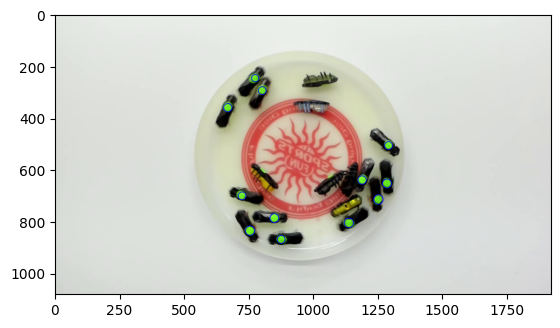

1 [698 685  16]
1 [763 847  17]
1 [1291  524   16]
1 [1273  673   17]
1 [865 787  16]
1 [1229  739   16]
1 [793 233  16]
1 [1177  653   15]
1 [679 337  15]
1 [857 865  15]
1 [1099  811   14]
1 [827 271  17]


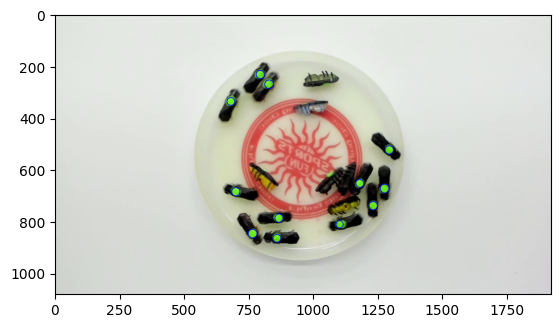

2 [1165  670   17]
2 [697 316  16]
2 [763 835  14]
2 [1267  695   16]
2 [867 845  16]
2 [811 220  18]
2 [677 667  17]
2 [851 251  17]
2 [1077  817   18]
2 [883 775  22]
2 [1289  547   14]
2 [1213  761   19]


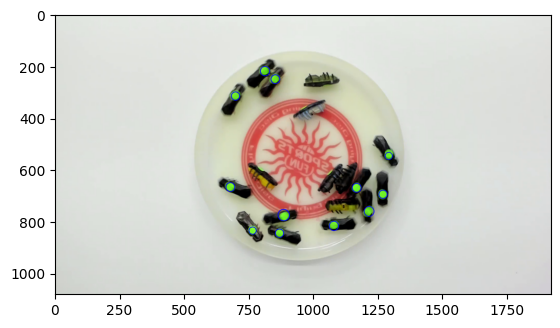

In [2]:
%matplotlib inline

min_r, max_r = 10, 30
isolate_green = True
isolate_orange = False

# Process the first 5 frames
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
for time_idx in range(3):

    t[time_idx] = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
    ret, frame = cap.read()
    if not ret:
        break

    circles = find_circles(frame, isolate_green=isolate_green, isolate_orange=isolate_orange, min_r=min_r, max_r=max_r)

    if circles is not None:
        circles = np.uint16(np.around(circles))
        for circ_stats in circles[0, :]:
            center = (circ_stats[0], circ_stats[1]) 
            radius = circ_stats[2]
            cv2.circle(frame, center, radius, (255, 0, 0), 2)
            x_t[time_idx], y_t[time_idx] = center
            print(time_idx, circ_stats)

    plt.figure()
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.show()